# Case file 5 · The Colour Alibi: a palette that does not lie

<a href="https://colab.research.google.com/github/umanets/pixelsprite/blob/main/learn/05_palette.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A model that picks colours needs a menu of colours: a **palette**. We build one with k-means, measure the error
in a colour space that matches human eyes (OKLab), and learn why the *average* error can hide real damage.

**Time:** about 1 minute. **You will learn:** sRGB vs OKLab, k-means clustering, ΔE (colour difference),
mean vs worst case.

In [1]:
try:
    import pixelsprite
except ImportError:
    %pip -q install "pixelsprite[learn] @ git+https://github.com/umanets/pixelsprite"
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from pixelsprite import sheet, rgba_from_index
from pixelsprite.colour import srgb_to_oklab
from pixelsprite.data import load_shard

sprites = load_shard(n=6000, seed=0)
solid = sprites.rgba[sprites.mask][:, :3]
colours, counts = np.unique(solid, axis=0, return_counts=True)
print(f"{len(solid):,} solid pixels, {len(colours):,} distinct colours")

936,091 solid pixels, 4,071 distinct colours


## 1. Why not just RGB distance?
RGB numbers describe how much red, green and blue light the screen emits, not how different two colours *look*.
**OKLab** is built so that equal distances look roughly equally different: L is lightness, a is green↔red, b is blue↔yellow.

In [3]:
pairs = {"dark blue vs darker blue": ([20, 20, 120], [20, 20, 90]), "yellow vs lighter yellow": ([230, 220, 40], [230, 220, 70])}
for name, (c1, c2) in pairs.items():
    rgb_d = np.linalg.norm(np.subtract(c1, c2))
    lab_d = 100 * np.linalg.norm(srgb_to_oklab(np.array(c1, np.uint8)) - srgb_to_oklab(np.array(c2, np.uint8)))
    print(f"{name:26}: RGB distance {rgb_d:5.1f}   OKLab ΔE {lab_d:5.2f}")
# Same RGB step (30), but the eye notices the blue change much more than the yellow one: OKLab agrees.

dark blue vs darker blue  : RGB distance  30.0   OKLab ΔE  5.43
yellow vs lighter yellow  : RGB distance  30.0   OKLab ΔE  1.49


## 2. k-means: find K colours that represent all the others
1. Pick K starting colours. 2. Give every colour to its nearest centre. 3. Move each centre to the average of its
colours (weighted by how many pixels use them). Repeat 2–3 until nothing moves. All of it in OKLab.

In [4]:
def kmeans(lab, weight, K, iters=40, seed=0):
    g = torch.Generator().manual_seed(seed)
    lab, weight = torch.as_tensor(lab), torch.as_tensor(weight, dtype=torch.float64)
    centres = lab[torch.multinomial(weight, K, replacement=False, generator=g)].clone()
    for _ in range(iters):
        owner = torch.cdist(lab, centres).argmin(1)                     # step 2
        for k in range(K):                                             # step 3
            sel = owner == k
            if sel.any():
                centres[k] = (lab[sel] * weight[sel, None]).sum(0) / weight[sel].sum()
    return centres.numpy(), owner.numpy()

lab = srgb_to_oklab(colours)
results = {}
for K in (16, 64, 256):
    centres, owner = kmeans(lab, counts, K)
    err = 100 * np.linalg.norm(lab - centres[owner], axis=1)             # ΔE of every distinct colour
    results[K] = (centres, owner, err)
    print(f"K = {K:3}: mean ΔE {np.average(err, weights=counts):5.2f}   worst ΔE {err.max():5.1f}")

K =  16: mean ΔE  3.80   worst ΔE  23.5


K =  64: mean ΔE  2.06   worst ΔE  20.3


K = 256: mean ΔE  1.16   worst ΔE  17.1


## 3. The average hides the damage
Snap every sprite to the K = 64 palette. Most look identical. Now sort sprites by their **own worst** pixel error and
look at the bottom of the list: entire colour families (often purples and lilacs) can be pushed into a neighbour.

sprites with a pixel off by more than 10 ΔE: 5.8%


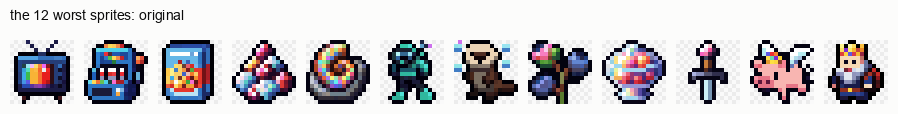

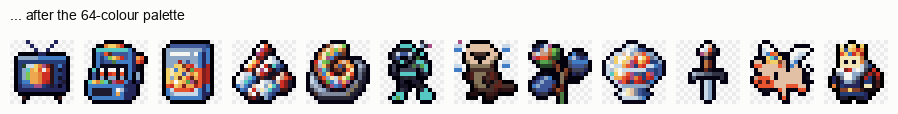

In [5]:
K = 64
centres, owner, err = results[K]
# palette colour = the real colour closest to each centre (so the palette contains real sprite colours)
pal_idx = [int(np.argmin(np.linalg.norm(lab - c, axis=1))) for c in centres]
palette = colours[pal_idx]
lookup = {tuple(c): o for c, o in zip(colours, owner)}

def quantise(rgba):
    idx = np.full(rgba.shape[:2], -1)
    m = rgba[..., 3] > 0
    idx[m] = [lookup[tuple(c)] for c in rgba[m][:, :3]]
    return idx

worst = []
for s in sprites.rgba:
    m = s[..., 3] > 0
    d = 100 * np.linalg.norm(srgb_to_oklab(s[m][:, :3]) - srgb_to_oklab(palette[quantise(s)[m]]), axis=1)
    worst.append(d.max())
order = np.argsort(worst)[::-1][:12]
print(f"sprites with a pixel off by more than 10 ΔE: {100 * np.mean(np.array(worst) > 10):.1f}%")
display(sheet([sprites.rgba[i] for i in order], "the 12 worst sprites: original", scale=4, cols=12))
display(sheet([rgba_from_index(quantise(sprites.rgba[i]), palette) for i in order], f"... after the {K}-colour palette", scale=4, cols=12))

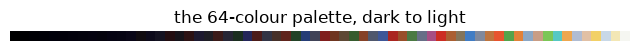

In [6]:
plt.figure(figsize=(8, 1.2)); plt.imshow(palette[np.argsort(srgb_to_oklab(palette)[:, 0])][None]); plt.axis("off")
plt.title(f"the {K}-colour palette, dark to light"); plt.show()

## Your turn
1. Rerun section 3 with K = 256. How many sprites are still off by more than 10 ΔE?
2. Run k-means in RGB instead of OKLab (use `colours.astype(float)` as `lab`). Which palette looks better on the worst sprites?